In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.core.viz.style import apply_style, ITALY_C, EU_C, PEER_C
apply_style()


# Pillar 1 — Municipal Fiscal Policy & Resource Allocation: How Does Cesena Collect and Spend Public Resources Compared to Peers?

This notebook examines the municipal balance sheets of **Cesena** (`040007`, Cadastral `C573`, NUTS3 `ITH58`) against two benchmark groups in Emilia-Romagna:
1. **Core Romagna & Mid-Sized Peers (6 peers, excluding Cesena):** Forlì (`040012`), Rimini (`099014`), Ravenna (`039014`), Imola (`037032`), Carpi (`036005`), and Reggio nell'Emilia (`035033`).
2. **All 12 Emilia-Romagna Peers (excluding Cesena):** Core peers plus Faenza (`039010`), Ferrara (`038008`), Modena (`036023`), Parma (`034027`), Piacenza (`033032`), and Bologna (`037006`).

**Methodological rules & accounting break:**
- **No silent splicing across the 2016 accounting harmonization break:** Italian municipalities transitioned from the historical `D.P.R. 194/1996` structure (`2008–2015`, flagged `flag = "break_dlgs118"`) to the harmonized `D.Lgs. 118/2011` Mission/Program classification (`2016+`) with the *Fondo Pluriennale Vincolato* (FPV) and *Fondo Crediti di Dubbia Esigibilità* (FCDE). Growth rates and regime averages are computed strictly *within* each regime, never across the `2015 -> 2016` boundary.
- **Constant 2020 euro per capita:** All nominal euro series are deflated to constant 2020 prices using the Italian national CPI/HICP deflator (`core.deflators.italy_deflator`) and divided by ISTAT Jan-1 resident population.
- **Descriptive only:** Every comparison and rank is descriptive, never causal.

In [2]:
from cifresignificative.studies.cesena.analysis.data import (
    load_fiscal, load_missions, load_demography, load_panel_comuni,
    cesena_vs_peers_series, peer_median_ex_cesena,
)
from cifresignificative.studies.cesena.analysis.fiscal import (
    mission_allocation_summary, compare_fiscal_regimes, capital_funding_breakdown,
)

fiscal = load_fiscal()
missions = load_missions()
demo = load_demography()
panel = load_panel_comuni()

cov = fiscal.pivot_table(index="year", columns="budget_type", values="comune_id", aggfunc="count", fill_value=0)
print("Municipal budget coverage across the 13 ER municipalities (rows by year and budget_type):")
display(cov.T)
print("Regime & break flags by year:", fiscal.groupby(["regime", "flag", "budget_type"])["year"].agg(["min", "max", "count"]).to_dict("index"))

Municipal budget coverage across the 13 ER municipalities (rows by year and budget_type):


year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
budget_type,,,,,,,,,,,,,,,
consuntivo,13,13,13,13,13,13,13,13,13,13,13,13,13,13,0
preventivo,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13


Regime & break flags by year: {('dlgs118', '', 'consuntivo'): {'min': 2016, 'max': 2021, 'count': 78}, ('dlgs118', 'preventivo', 'preventivo'): {'min': 2022, 'max': 2022, 'count': 13}, ('dpr194', 'break_dlgs118', 'consuntivo'): {'min': 2008, 'max': 2015, 'count': 104}}


## 1. Current vs. Capital Expenditure & the 2016 Harmonization Break
We compare Cesena's real per-capita current expenditure (`Titolo I`, *Spese correnti*) and capital expenditure (`Titolo II`, *Spese in conto capitale*, accrual commitments and cash outlays) against the Core Peer median and All-ER Peer median separately in `2008–2015` (`dpr194`) and `2016–2021` (`dlgs118` consuntivo, plus `2022` preventivo).

Cesena vs Core Peer median (6 peers ex Cesena) and rank among all 13 ER municipalities, by accounting regime:


,regime,regime_label,metric,cesena_mean,peer_median,gap_vs_peers,gap_pct,rank_1_to_n,n_comuni
0,dpr194,D.P.R. 194/1996 (2008-2015),spese_correnti_comp_real_pc,841.57,940.58,-99.01,-10.53,13,13
1,dpr194,D.P.R. 194/1996 (2008-2015),spese_capitale_comp_real_pc,232.20,196.01,36.18,18.46,5,13
2,dpr194,D.P.R. 194/1996 (2008-2015),capital_share_pct,21.17,16.52,4.65,28.13,5,13
3,dpr194,D.P.R. 194/1996 (2008-2015),contributi_investimenti_comp_real_pc,85.91,115.75,-29.84,-25.78,8,13
4,dpr194,D.P.R. 194/1996 (2008-2015),alienazioni_comp_real_pc,51.05,35.21,15.83,44.95,4,13
5,dpr194,D.P.R. 194/1996 (2008-2015),accensione_mutui_comp_real_pc,31.17,19.29,11.88,61.59,6,13
6,dpr194,D.P.R. 194/1996 (2008-2015),entrate_tributarie_comp_real_pc,533.58,591.14,-57.56,-9.74,12,13
7,dpr194,D.P.R. 194/1996 (2008-2015),imposte_tasse_comp_real_pc,378.55,421.58,-43.03,-10.21,12,13
8,dpr194,D.P.R. 194/1996 (2008-2015),imu_ici_comp_real_pc,230.90,267.78,-36.88,-13.77,11,13
9,dpr194,D.P.R. 194/1996 (2008-2015),mef_addizionale_real_pc,60.01,75.38,-15.37,-20.39,12,13



--- Current expenditure (comp., 2020 EUR/pc) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers,missing_core_peers
0,2008,820.41,970.91,1008.48,-150.50,6,
1,2009,827.80,954.10,961.74,-126.31,6,
2,2010,830.12,950.46,952.89,-120.34,6,
3,2011,775.86,917.44,917.44,-141.58,6,
4,2012,792.82,863.98,882.48,-71.15,6,
5,2013,918.02,946.39,1014.12,-28.37,6,
6,2014,882.22,960.05,1003.19,-77.83,6,
7,2015,885.34,966.64,1012.04,-81.30,6,
8,2016,819.96,991.64,1019.23,-171.68,6,
9,2017,826.74,972.69,1008.46,-145.95,6,



--- Capital expenditure (comp., 2020 EUR/pc) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers,missing_core_peers
0,2008,388.17,533.57,513.74,-145.40,6,
1,2009,283.02,283.18,287.50,-0.15,6,
2,2010,321.36,183.44,230.09,137.92,6,
3,2011,208.55,125.35,138.68,83.20,6,
4,2012,129.82,103.55,103.55,26.27,6,
5,2013,145.33,212.74,196.16,-67.42,6,
6,2014,127.58,95.71,108.06,31.87,6,
7,2015,253.74,119.52,150.49,134.22,6,
8,2016,122.41,149.01,140.51,-26.60,6,
9,2017,139.81,100.73,119.75,39.08,6,



--- Capital share of primary expenditure (%) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers,missing_core_peers
0,2008,32.12,34.34,31.89,-2.23,6,
1,2009,25.48,22.71,20.39,2.77,6,
2,2010,27.91,15.57,17.71,12.34,6,
3,2011,21.18,13.10,13.09,8.08,6,
4,2012,14.07,10.65,10.65,3.42,6,
5,2013,13.67,18.05,15.86,-4.38,6,
6,2014,12.63,8.78,8.96,3.85,6,
7,2015,22.28,11.55,12.35,10.72,6,
8,2016,12.99,15.06,12.91,-2.07,6,
9,2017,14.46,10.31,11.42,4.16,6,


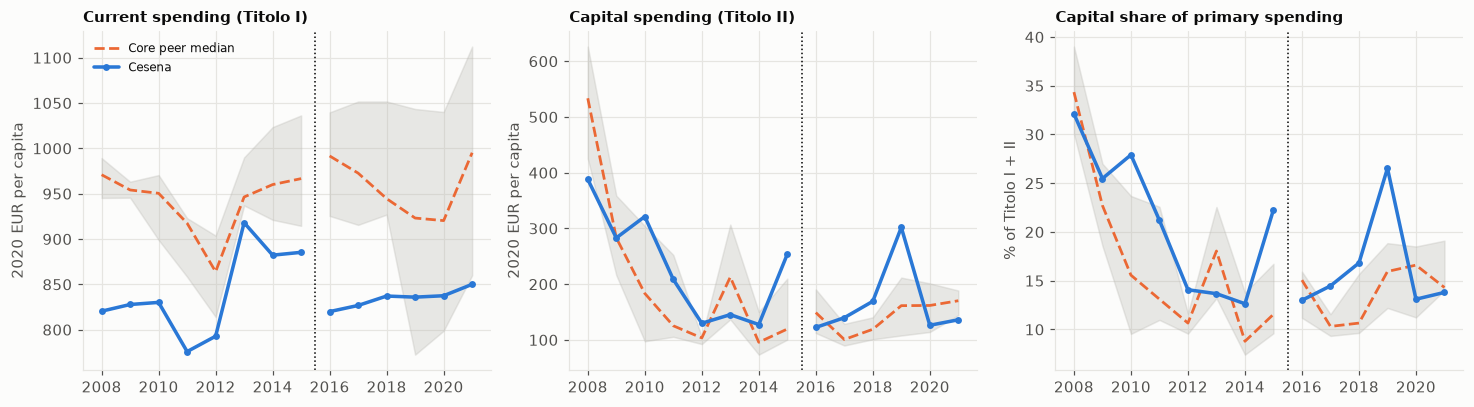

In [3]:
reg_comp = compare_fiscal_regimes(fiscal, core_only=True)
print("Cesena vs Core Peer median (6 peers ex Cesena) and rank among all 13 ER municipalities, by accounting regime:")
display(reg_comp.round(2))

cons = fiscal[fiscal["budget_type"] == "consuntivo"].copy()
for col, label in [
    ("spese_correnti_comp_real_pc", "Current expenditure (comp., 2020 EUR/pc)"),
    ("spese_capitale_comp_real_pc", "Capital expenditure (comp., 2020 EUR/pc)"),
    ("capital_share_pct", "Capital share of primary expenditure (%)"),
]:
    ser = cesena_vs_peers_series(cons, col, core_only=True)
    print(f"\n--- {label} ---")
    display(ser[["year", "cesena", "core_peer_median", "er_peer_median", "gap_vs_benchmark", "n_core_peers", "missing_core_peers"]].round(2))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
for ax, (col, title, yl) in zip(axes, [
    ("spese_correnti_comp_real_pc", "Current spending (Titolo I)", "2020 EUR per capita"),
    ("spese_capitale_comp_real_pc", "Capital spending (Titolo II)", "2020 EUR per capita"),
    ("capital_share_pct", "Capital share of primary spending", "% of Titolo I + II"),
]):
    s = cesena_vs_peers_series(cons, col, core_only=True)
    for reg_cond in [s["year"] <= 2015, s["year"] >= 2016]:
        sub = s[reg_cond]
        ax.plot(sub["year"], sub["core_peer_median"], color=EU_C, ls="--", lw=1.8, label="Core peer median" if reg_cond.iloc[0] else None)
        ax.fill_between(sub["year"], sub["core_peer_p25"], sub["core_peer_p75"], color=PEER_C, alpha=0.3)
        ax.plot(sub["year"], sub["cesena"], color=ITALY_C, lw=2.3, marker="o", ms=3.5, label="Cesena" if reg_cond.iloc[0] else None)
    ax.axvline(2015.5, color="k", ls=":", lw=1.0)
    ax.set_title(title, fontsize=9.5)
    ax.set_ylabel(yl)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. Harmonized Expenditure by Mission (`2016–2021` Consuntivo)
Under `D.Lgs. 118/2011`, municipal expenditure is classified into standardized Missions (`M01` General Institutional Services through `M50` Public Debt). OpenBilanci's parent Mission JSON nodes suffer from a `NaN`-propagation bug whenever a single child Program has zero capital outlays (e.g., Cesena 2021 Mission 05 and Mission 11); our parser (`core.sources.bdap._mission_composition`) reconstructs every Mission from the sum of its child Program nodes (`0` discrepancy against the budget headline).

Harmonized expenditure by Mission (2016-2021 consuntivo average, constant 2020 EUR per capita, Cesena vs Core Peer median):


,mission_code,mission_label,cesena_correnti_real_pc,peer_correnti_real_pc,gap_correnti_real_pc,cesena_capitale_real_pc,peer_capitale_real_pc,gap_capitale_real_pc,cesena_totale_real_pc,peer_totale_real_pc,cesena_correnti_share_pct,cesena_capitale_share_pct
0,M01,"Servizi istituzionali, generali e di gestione",180.80,181.51,-0.71,44.94,16.01,28.92,268.91,227.10,21.66,27.08
1,M09,Sviluppo sostenibile e tutela del territorio e...,200.55,193.35,7.21,13.88,9.07,4.81,214.43,205.57,24.03,8.36
2,M10,Trasporti e diritto alla mobilità,97.30,75.59,21.71,44.48,32.61,11.87,141.78,110.31,11.66,26.80
3,M12,"Diritti sociali, politiche sociali e famiglia",131.06,181.40,-50.33,5.57,6.99,-1.42,136.63,186.72,15.70,3.36
4,M04,Istruzione e diritto allo studio,104.59,142.06,-37.47,19.42,14.62,4.80,124.02,157.09,12.53,11.71
5,M05,Tutela e valorizzazione dei beni e attività cu...,42.21,58.67,-16.46,10.36,12.09,-1.73,52.57,78.94,5.06,6.24
6,M03,Ordine pubblico e sicurezza,40.07,57.28,-17.22,2.84,1.67,1.17,42.90,58.81,4.80,1.71
7,M50,Debito pubblico,3.12,0.00,3.12,0.00,0.00,0.00,36.67,51.32,0.37,0.00
8,M06,"Politiche giovanili, sport e tempo libero",10.95,19.76,-8.81,13.38,11.73,1.65,24.33,30.56,1.31,8.06
9,M08,Assetto del territorio ed edilizia abitativa,6.63,9.78,-3.15,10.12,13.65,-3.53,16.83,25.84,0.79,6.10


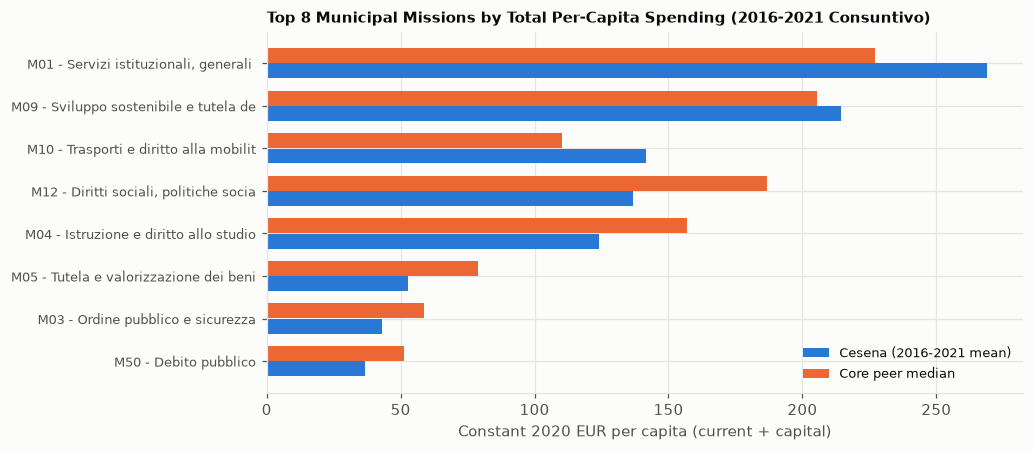

In [4]:
m_sum = mission_allocation_summary(missions, demo, years=(2016, 2017, 2018, 2019, 2020, 2021), core_only=True)
print("Harmonized expenditure by Mission (2016-2021 consuntivo average, constant 2020 EUR per capita, Cesena vs Core Peer median):")
display(m_sum[[
    "mission_code", "mission_label",
    "cesena_correnti_real_pc", "peer_correnti_real_pc", "gap_correnti_real_pc",
    "cesena_capitale_real_pc", "peer_capitale_real_pc", "gap_capitale_real_pc",
    "cesena_totale_real_pc", "peer_totale_real_pc", "cesena_correnti_share_pct", "cesena_capitale_share_pct",
]].round(2))

top_m = m_sum.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 4.2))
y = np.arange(len(top_m))
ax.barh(y - 0.18, top_m["cesena_totale_real_pc"], height=0.35, color=ITALY_C, label="Cesena (2016-2021 mean)")
ax.barh(y + 0.18, top_m["peer_totale_real_pc"], height=0.35, color=EU_C, label="Core peer median")
ax.set_yticks(y, [f"{r.mission_code} - {r.mission_label[:32]}" for _, r in top_m.iterrows()], fontsize=8.5)
ax.set_xlabel("Constant 2020 EUR per capita (current + capital)")
ax.set_title("Top 8 Municipal Missions by Total Per-Capita Spending (2016-2021 Consuntivo)", fontsize=10)
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

## 3. Capital Investment Funding Structure: Grants, Asset Sales, Borrowing & Multi-Year FPV (`2008–2021`)
How did Cesena fund its capital expenditure in `2016–2021`?
We break down municipal capital resources across:
1. **Capital Grants & Transfers (`Contributi agli investimenti`, Titolo IV):** State, regional, and EU capital subsidies.
2. **Asset Sales (`Alienazioni di beni patrimoniali`, Titolo IV):** Real estate and asset disposal.
3. **New Borrowing (`Accensione mutui e prestiti`, Titolo VI):** Long-term investment financing (primarily Cassa Depositi e Prestiti).
4. **Capital Multi-Year Committed Fund (`FPV capitale`, Quadro 2.1):** *Fondo Pluriennale Vincolato per spese in conto capitale*, introduced by `D.Lgs. 118/2011` to carry resources for multi-year works between budget years. It is a stock, not a source of money: a high value can reflect planned works as well as slow execution.
5. **Applied Administrative Surplus (`Avanzo di amministrazione applicato`, Quadro 2.1):** Accumulated unencumbered reserves channeled into capital outlays.

Cesena Capital Expenditure vs. Funding Sources per Capita (constant 2020 EUR/pc, Cesena vs. Core Peer median):


,year,regime,cesena_spese_capitale_pc,peer_spese_capitale_pc,cesena_contributi_investimenti_pc,peer_contributi_investimenti_pc,cesena_alienazioni_pc,peer_alienazioni_pc,cesena_accensione_mutui_pc,peer_accensione_mutui_pc,cesena_fpv_capitale_pc,peer_fpv_capitale_pc,cesena_avanzo_amministrazione_pc,peer_avanzo_amministrazione_pc
0,2008,dpr194,388.17,533.57,98.34,176.07,108.66,37.90,44.31,25.03,NaN,NaN,NaN,NaN
1,2009,dpr194,283.02,283.18,100.20,132.57,19.53,47.29,59.52,6.22,NaN,NaN,NaN,NaN
2,2010,dpr194,321.36,183.44,100.31,110.70,9.36,27.01,56.10,13.85,NaN,NaN,NaN,NaN
3,2011,dpr194,208.55,125.35,74.74,99.08,26.74,32.51,33.11,0.00,NaN,NaN,NaN,NaN
4,2012,dpr194,129.82,103.55,67.97,78.81,30.31,5.51,0.00,0.00,NaN,NaN,NaN,NaN
5,2013,dpr194,145.33,212.74,104.51,86.68,30.13,29.13,0.00,0.00,NaN,NaN,NaN,NaN
6,2014,dpr194,127.58,95.71,61.09,46.81,3.23,8.54,44.39,0.00,NaN,NaN,NaN,NaN
7,2015,dpr194,253.74,119.52,80.09,78.56,180.41,18.61,11.95,17.29,NaN,NaN,NaN,NaN
8,2016,dlgs118,122.41,149.01,71.43,36.90,5.91,9.64,61.64,20.03,207.51,178.24,28.84,60.61
9,2017,dlgs118,139.81,100.73,5.52,25.34,3.54,12.42,22.70,0.00,301.50,142.47,44.59,56.90


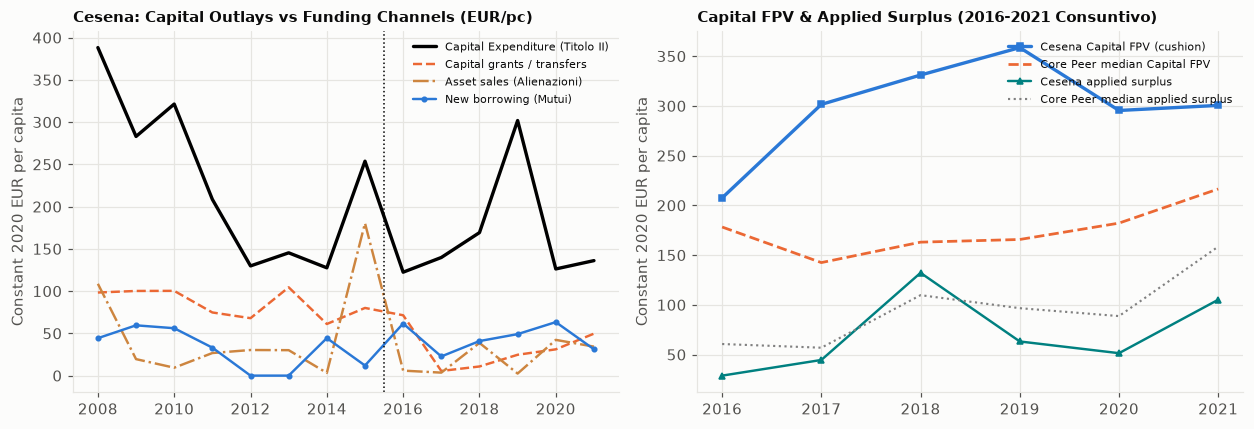

In [5]:
cap_fund = capital_funding_breakdown(fiscal, core_only=True)
print("Cesena Capital Expenditure vs. Funding Sources per Capita (constant 2020 EUR/pc, Cesena vs. Core Peer median):")
display(cap_fund.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
# Plot 1: Capital Funding Breakdown for Cesena over time
axes[0].plot(cap_fund["year"], cap_fund["cesena_spese_capitale_pc"], color="black", lw=2.2, label="Capital Expenditure (Titolo II)")
axes[0].plot(cap_fund["year"], cap_fund["cesena_contributi_investimenti_pc"], color=EU_C, lw=1.6, ls="--", label="Capital grants / transfers")
axes[0].plot(cap_fund["year"], cap_fund["cesena_alienazioni_pc"], color="peru", lw=1.6, ls="-.", label="Asset sales (Alienazioni)")
axes[0].plot(cap_fund["year"], cap_fund["cesena_accensione_mutui_pc"], color=ITALY_C, lw=1.6, marker="o", ms=3.0, label="New borrowing (Mutui)")
axes[0].axvline(2015.5, color="k", ls=":", lw=1.0)
axes[0].set_title("Cesena: Capital Outlays vs Funding Channels (EUR/pc)", fontsize=9.5)
axes[0].set_ylabel("Constant 2020 EUR per capita")
axes[0].legend(fontsize=7.5)

# Plot 2: Multi-Year Capital FPV and Applied Surplus in 2016-2021 (D.Lgs. 118)
sub_h = cap_fund[cap_fund["year"] >= 2016]
axes[1].plot(sub_h["year"], sub_h["cesena_fpv_capitale_pc"], color=ITALY_C, lw=2.2, marker="s", ms=4.0, label="Cesena Capital FPV (cushion)")
axes[1].plot(sub_h["year"], sub_h["peer_fpv_capitale_pc"], color=EU_C, lw=1.8, ls="--", label="Core Peer median Capital FPV")
axes[1].plot(sub_h["year"], sub_h["cesena_avanzo_amministrazione_pc"], color="teal", lw=1.6, marker="^", ms=3.5, label="Cesena applied surplus")
axes[1].plot(sub_h["year"], sub_h["peer_avanzo_amministrazione_pc"], color="gray", lw=1.4, ls=":", label="Core Peer median applied surplus")
axes[1].set_title("Capital FPV & Applied Surplus (2016-2021 Consuntivo)", fontsize=9.5)
axes[1].set_ylabel("Constant 2020 EUR per capita")
axes[1].legend(fontsize=7.5)
plt.tight_layout()
plt.show()

## 4. Local Tax Pressure: Own Taxes, IMU/ICI, and Addizionale Comunale IRPEF (`2008–2024`)
We inspect total municipal tax revenues (`Titolo I, Tipologia 101 Imposte, tasse e proventi assimilati`), property taxation (`IMU/ICI`), and the municipal personal income tax surcharge (`Addizionale Comunale IRPEF`), combining the municipal balance sheets (`2008–2021`) with the MEF tax declarations panel (`2008–2024`).

MEF Addizionale Comunale IRPEF per resident (constant 2020 EUR, 2008-2024):


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers
0,2008,61.23,79.84,82.72,-18.61,6
1,2009,60.14,76.82,79.98,-16.69,6
2,2010,59.45,75.52,78.53,-16.07,6
3,2011,59.05,69.74,76.79,-10.69,6
4,2012,56.89,71.48,78.58,-14.59,6
5,2013,56.60,76.33,88.46,-19.73,6
6,2014,62.38,75.70,85.92,-13.33,6
7,2015,64.36,85.37,93.35,-21.01,6
8,2016,65.88,85.83,93.64,-19.95,6
9,2017,66.90,85.58,94.17,-18.68,6


Cesena tax revenue breakdown (2008-2021 consuntivo, constant 2020 EUR per capita):


,year,regime,entrate_tributarie_comp_real_pc,imposte_tasse_comp_real_pc,imu_ici_comp_real_pc,addizionale_irpef_comp_real_pc,mef_addizionale_real_pc,effective_surcharge_rate_pct
150,2008,dpr194,NaN,0.00,189.43,58.39,61.23,0.37
151,2009,dpr194,308.55,306.08,195.70,54.64,60.14,0.36
152,2010,dpr194,318.07,315.50,201.15,57.21,59.45,0.36
153,2011,dpr194,547.53,349.71,189.66,57.36,59.05,0.36
154,2012,dpr194,585.12,437.29,346.34,55.19,56.89,0.37
155,2013,dpr194,609.96,474.81,236.24,54.32,56.60,0.37
156,2014,dpr194,721.02,603.88,246.30,63.72,62.38,0.41
157,2015,dpr194,644.80,541.15,242.34,24.23,64.36,0.41
158,2016,dlgs118,667.01,513.81,259.61,63.36,65.88,0.41
159,2017,dlgs118,667.22,518.92,255.27,64.31,66.90,0.42


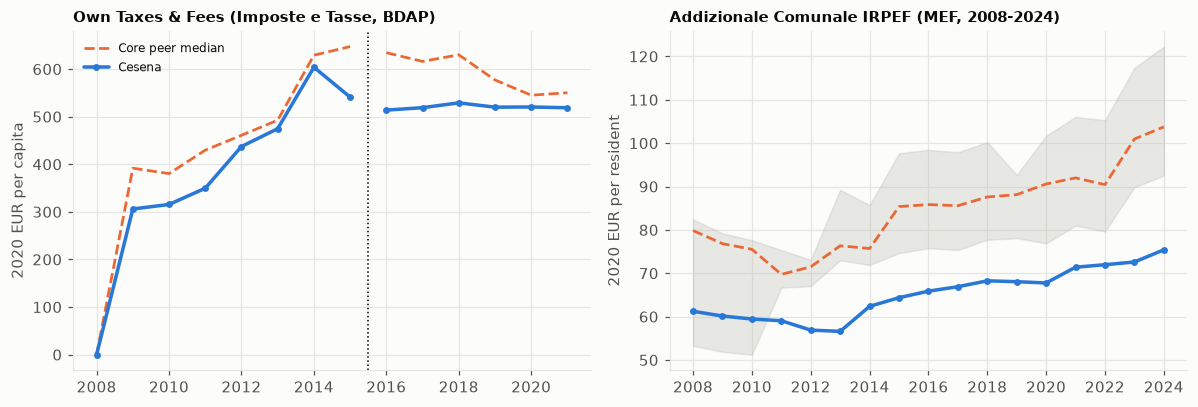

In [6]:
tax_mef = cesena_vs_peers_series(panel[panel["year"] <= 2024], "mef_addizionale_real_pc", core_only=True)
print("MEF Addizionale Comunale IRPEF per resident (constant 2020 EUR, 2008-2024):")
display(tax_mef[["year", "cesena", "core_peer_median", "er_peer_median", "gap_vs_benchmark", "n_core_peers"]].round(2))

fisc_ces = fiscal[(fiscal["comune_id"] == "040007") & (fiscal["budget_type"] == "consuntivo")][
    ["year", "regime", "entrate_tributarie_comp_real_pc", "imposte_tasse_comp_real_pc", "imu_ici_comp_real_pc", "addizionale_irpef_comp_real_pc", "mef_addizionale_real_pc", "effective_surcharge_rate_pct"]
]
print("Cesena tax revenue breakdown (2008-2021 consuntivo, constant 2020 EUR per capita):")
display(fisc_ces.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
s_imp = cesena_vs_peers_series(cons, "imposte_tasse_comp_real_pc", core_only=True)
for reg_cond in [s_imp["year"] <= 2015, s_imp["year"] >= 2016]:
    sub = s_imp[reg_cond]
    axes[0].plot(sub["year"], sub["core_peer_median"], color=EU_C, ls="--", lw=1.8, label="Core peer median" if reg_cond.iloc[0] else None)
    axes[0].plot(sub["year"], sub["cesena"], color=ITALY_C, lw=2.3, marker="o", ms=3.5, label="Cesena" if reg_cond.iloc[0] else None)
axes[0].axvline(2015.5, color="k", ls=":", lw=1.0)
axes[0].set_title("Own Taxes & Fees (Imposte e Tasse, BDAP)", fontsize=9.5)
axes[0].set_ylabel("2020 EUR per capita")
axes[0].legend(fontsize=8)

axes[1].plot(tax_mef["year"], tax_mef["core_peer_median"], color=EU_C, ls="--", lw=1.8, label="Core peer median")
axes[1].fill_between(tax_mef["year"], tax_mef["core_peer_p25"], tax_mef["core_peer_p75"], color=PEER_C, alpha=0.3)
axes[1].plot(tax_mef["year"], tax_mef["cesena"], color=ITALY_C, lw=2.3, marker="o", ms=3.5, label="Cesena")
axes[1].set_title("Addizionale Comunale IRPEF (MEF, 2008-2024)", fontsize=9.5)
axes[1].set_ylabel("2020 EUR per resident")
plt.tight_layout()
plt.show()

## 5. Balance Sheet Rigidity & Revenue Collection Capacity
We examine two structural indicators of municipal financial health:
1. **Official Balance Sheet Rigidity (`rigidity_official_pct`):** `(Spesa di personale + Rimborso prestiti Titolo IV) / Entrate correnti (Titoli I + II + III) * 100`. For `2016–2018`, when OpenBilanci's harmonized tree omits the macroaggregato breakdown, personnel expenditure (`Macroaggregato 101 Redditi da lavoro dipendente`) is supplemented directly from the Ministry of the Interior (`Finanza Locale CCOX Quadro 8/10`).
2. **Revenue Collection Capacity (`collection_rate_correnti_pct` & `collection_rate_proprie_pct`):** Cash collections (`Riscossioni in c/competenza + c/residui`) divided by accrual assessments (`Accertamenti`) for total current revenues and own revenues (`Titolo I + Titolo III`).


--- Official rigidity index: (Personnel + Debt principal) / Current revenues (%) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers,missing_core_peers
0,2008,66.20,72.92,69.53,-6.72,6,
1,2009,42.13,48.76,46.96,-6.62,6,
2,2010,41.44,47.31,43.14,-5.87,6,
3,2011,42.06,45.31,42.63,-3.25,6,
4,2012,39.31,47.31,38.87,-8.00,6,
5,2013,31.50,34.30,35.58,-2.80,6,
6,2014,30.47,31.67,32.82,-1.20,6,
7,2015,27.39,30.10,31.61,-2.71,6,
8,2016,26.20,25.65,26.79,0.55,6,
9,2017,26.71,25.48,26.16,1.23,6,



--- Current revenue cash-to-accrual collection rate (%) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers,missing_core_peers
0,2008,99.36,100.21,98.90,-0.85,6,
1,2009,108.65,103.11,104.14,5.54,6,
2,2010,104.32,102.98,101.31,1.34,6,
3,2011,97.06,103.03,99.11,-5.97,6,
4,2012,116.07,106.03,101.33,10.04,6,
5,2013,98.31,95.18,94.47,3.12,6,
6,2014,99.26,102.03,101.36,-2.77,6,
7,2015,102.63,95.23,95.80,7.40,6,
8,2016,92.41,93.71,95.91,-1.30,6,
9,2017,88.88,93.23,95.04,-4.35,6,



--- Own revenue (Titolo I + III) cash-to-accrual collection rate (%) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers,missing_core_peers
0,2008,NaN,100.13,100.13,NaN,1,"Carpi, Forlì, Imola, Ravenna, Rimini"
1,2009,100.91,102.34,103.41,-1.43,6,
2,2010,103.11,102.16,99.88,0.95,6,
3,2011,96.31,100.93,97.91,-4.63,6,
4,2012,102.97,102.69,99.07,0.29,6,
5,2013,98.81,93.58,93.55,5.23,6,
6,2014,96.69,101.88,100.12,-5.18,6,
7,2015,103.80,95.00,96.47,8.80,6,
8,2016,91.94,92.47,94.82,-0.53,6,
9,2017,87.75,95.07,95.30,-7.32,6,


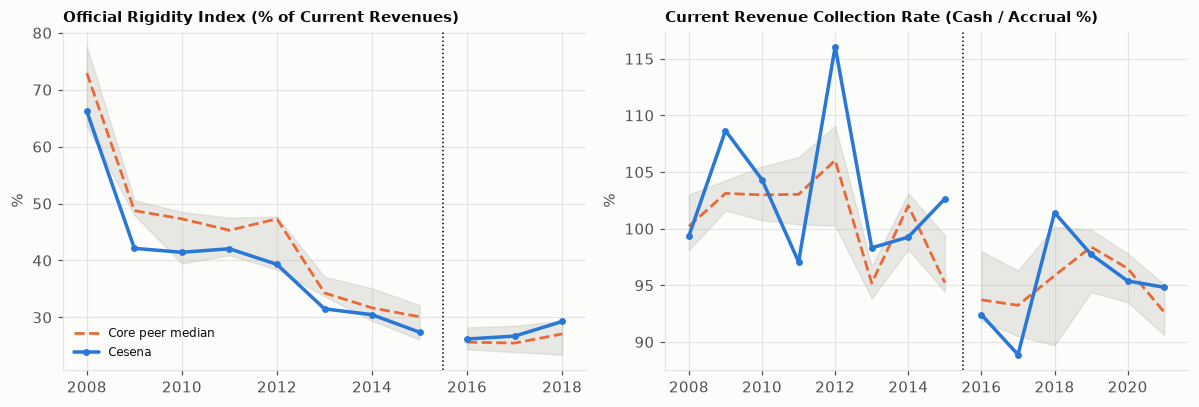

In [7]:
for col, lbl in [
    ("rigidity_official_pct", "Official rigidity index: (Personnel + Debt principal) / Current revenues (%)"),
    ("collection_rate_correnti_pct", "Current revenue cash-to-accrual collection rate (%)"),
    ("collection_rate_proprie_pct", "Own revenue (Titolo I + III) cash-to-accrual collection rate (%)"),
]:
    s = cesena_vs_peers_series(cons, col, core_only=True)
    print(f"\n--- {lbl} ---")
    display(s[["year", "cesena", "core_peer_median", "er_peer_median", "gap_vs_benchmark", "n_core_peers", "missing_core_peers"]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (col, title) in zip(axes, [
    ("rigidity_official_pct", "Official Rigidity Index (% of Current Revenues)"),
    ("collection_rate_correnti_pct", "Current Revenue Collection Rate (Cash / Accrual %)"),
]):
    s = cesena_vs_peers_series(cons, col, core_only=True)
    for reg_cond in [s["year"] <= 2015, s["year"] >= 2016]:
        sub = s[reg_cond]
        ax.plot(sub["year"], sub["core_peer_median"], color=EU_C, ls="--", lw=1.8, label="Core peer median" if reg_cond.iloc[0] else None)
        ax.fill_between(sub["year"], sub["core_peer_p25"], sub["core_peer_p75"], color=PEER_C, alpha=0.3)
        ax.plot(sub["year"], sub["cesena"], color=ITALY_C, lw=2.3, marker="o", ms=3.5, label="Cesena" if reg_cond.iloc[0] else None)
    ax.axvline(2015.5, color="k", ls=":", lw=1.0)
    ax.set_title(title, fontsize=9.5)
    ax.set_ylabel("%")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Consolidated Municipal Perimeter: *Unione dei Comuni Valle del Savio* & SIOPE Cash Accounts (`2016–2024`)
In Emilia-Romagna, municipalities differ sharply in how local public functions (social welfare, local police, civil protection, IT) are organized: some retain services on the direct municipal balance sheet, while others delegate them to an *Unione di Comuni* (*Unione dei Comuni Valle del Savio* for Cesena, *Unione della Romagna Faentina* for Faenza, *Unione Terre d'Argine* for Carpi, *Nuovo Circondario Imolese* for Imola, *Romagna Forlivese* for Forlì).

To test whether Cesena's lower apparent direct spending on social rights (`M12`) and local police (`M03`) reflects true expenditure containment or institutional externalization, we integrate MEF RGS **SIOPE cash expenditure accounts (`2016–2024`)** across all 13 benchmark municipalities and their associated Unioni, constructing a pro-rata **consolidated expenditure perimeter (`spese_consolidate_pc`)**.

SIOPE Municipal & Unione Consolidated Expenditure in 2024 (EUR per capita):


,entity_name,direct_correnti_pc,unione_correnti_pc,consolidated_correnti_pc,direct_personale_pc,consolidated_personale_pc,consolidated_capitale_pc
104,COMUNE DI BOLOGNA,1544.3,0.0,1544.3,435.9,435.9,586.0
111,COMUNE DI MODENA,1325.3,0.0,1325.3,312.9,312.9,446.8
114,COMUNE DI RAVENNA,1317.7,0.0,1317.7,293.7,293.7,338.3
116,COMUNE DI RIMINI,1277.9,0.0,1277.9,323.8,323.8,419.7
113,COMUNE DI PIACENZA,1203.7,0.0,1203.7,258.5,258.5,190.9
107,COMUNE DI FAENZA,892.4,685.6,1197.0,2.6,261.2,521.7
112,COMUNE DI PARMA,1115.5,0.0,1115.5,255.1,255.1,231.3
108,COMUNE DI FERRARA,1023.8,0.0,1023.8,313.6,313.6,368.9
110,COMUNE DI IMOLA,915.3,151.3,971.7,153.9,209.3,177.0
109,COMUNE DI FORLI',922.9,27.7,927.4,264.7,278.3,407.1



Cesena vs Core Peers Consolidated Benchmark (2024):


,metric_label,cesena,peer_median,gap_vs_peers,gap_pct,rank_desc,n_comuni
0,Direct Current Spending (EUR/pc),838.50,920.03,-81.52,-8.86,12,13
1,Unione Delegated Spending (EUR/pc),183.69,13.83,169.87,1228.56,3,13
2,Consolidated Current Spending (EUR/pc),917.26,949.55,-32.29,-3.40,11,13
3,Direct Personnel Spending (EUR/pc),234.99,239.34,-4.35,-1.82,9,13
4,Consolidated Personnel Spending (EUR/pc),285.43,285.96,-0.54,-0.19,7,13
5,Direct Capital Investment (EUR/pc),401.38,313.78,87.60,27.92,6,13
6,Consolidated Capital Investment (EUR/pc),425.92,313.78,112.14,35.74,4,13


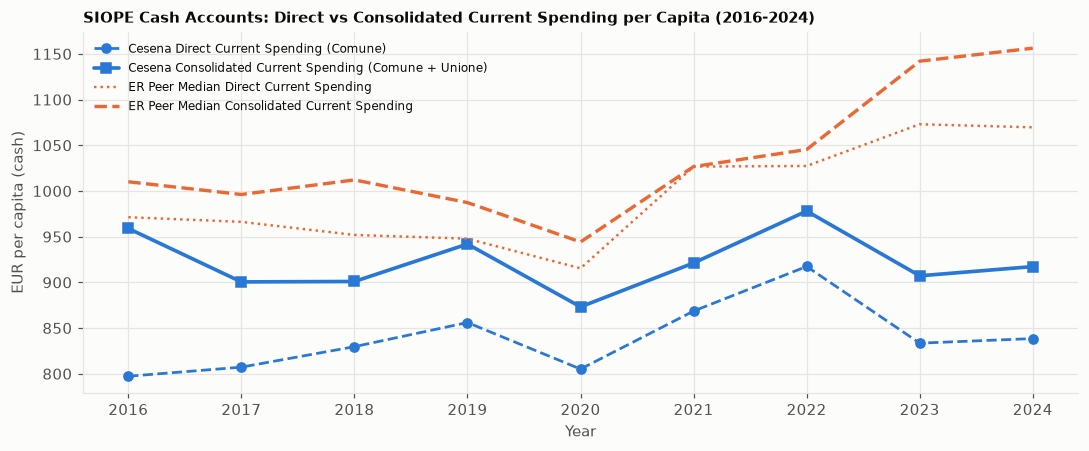

In [8]:
from cifresignificative.studies.cesena.analysis.data import load_siope_consolidated
from cifresignificative.studies.cesena.analysis.fiscal import summarize_consolidated_benchmarks

siope_cons = load_siope_consolidated()
print("SIOPE Municipal & Unione Consolidated Expenditure in 2024 (EUR per capita):")
tbl_2024 = siope_cons[siope_cons["year"] == 2024][
    ["entity_name", "direct_correnti_pc", "unione_correnti_pc", "consolidated_correnti_pc", "direct_personale_pc", "consolidated_personale_pc", "consolidated_capitale_pc"]
].sort_values("consolidated_correnti_pc", ascending=False)
display(tbl_2024.round(1))

bench_cons = summarize_consolidated_benchmarks(siope_cons, year=2024, core_only=True)
print("\nCesena vs Core Peers Consolidated Benchmark (2024):")
display(bench_cons[["metric_label", "cesena", "peer_median", "gap_vs_peers", "gap_pct", "rank_desc", "n_comuni"]].round(2))

fig, ax = plt.subplots(figsize=(10, 4.2))
ces_ts = siope_cons[siope_cons["comune_id"] == "040007"].sort_values("year")
peers_ts = siope_cons[siope_cons["comune_id"] != "040007"].groupby("year")[["direct_correnti_pc", "consolidated_correnti_pc"]].median()

ax.plot(ces_ts["year"], ces_ts["direct_correnti_pc"], color=ITALY_C, lw=1.8, ls="--", marker="o", label="Cesena Direct Current Spending (Comune)")
ax.plot(ces_ts["year"], ces_ts["consolidated_correnti_pc"], color=ITALY_C, lw=2.4, marker="s", label="Cesena Consolidated Current Spending (Comune + Unione)")
ax.plot(peers_ts.index, peers_ts["direct_correnti_pc"], color=EU_C, lw=1.6, ls=":", label="ER Peer Median Direct Current Spending")
ax.plot(peers_ts.index, peers_ts["consolidated_correnti_pc"], color=EU_C, lw=2.2, ls="--", label="ER Peer Median Consolidated Current Spending")
ax.set_title("SIOPE Cash Accounts: Direct vs Consolidated Current Spending per Capita (2016-2024)", fontsize=10)
ax.set_ylabel("EUR per capita (cash)")
ax.set_xlabel("Year")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Spending Against Standard Need and Service Output: SOSE / MEF OpenCivitas (2023)

OpenCivitas compares each Italian municipality's spending with a standard need and places its service output on a national scale:
1. **Fabbisogni Standard (Standard Expenditure Needs):** the modelled cost of standard services given demography, geography and deprivation.
2. **Spesa Storica (Historical Expenditure):** actual operating expenditure.
3. **Livelli Quantitativi delle Prestazioni (LQP, national deciles 1–10):** quantities of services delivered. The score counts quantities rather than quality, so it does not establish efficiency.

SOSE / MEF OpenCivitas Standard Needs & Service Levels across 13 ER Municipalities (2023):


,comune,tot_spesa_storica_eur_pc,tot_fabbisogno_standard_eur_pc,tot_diff_eur_pc,tot_diff_pct,tot_livello_spesa_0_10,tot_livello_servizi_0_10,tot_coord_spesa,tot_coord_servizi,quadrante_performance
0,Carpi,629.71,755.40,-125.69,-16.64,3,9,-2,4,virtuoso
1,Faenza,632.94,812.51,-179.57,-22.10,2,10,-3,5,virtuoso
2,Imola,786.28,849.79,-63.51,-7.47,5,9,0,4,virtuoso
3,Cesena,819.97,869.13,-49.16,-5.66,5,10,0,5,virtuoso
4,Forlì,830.69,831.36,-0.67,-0.08,5,10,0,5,virtuoso
5,Parma,917.80,904.08,13.72,1.52,6,7,1,2,alto_servizio_alta_spesa
6,Rimini,929.46,1050.74,-121.28,-11.54,4,5,-1,0,virtuoso
7,Reggio nell'Emilia,953.54,922.61,30.93,3.35,6,9,1,4,alto_servizio_alta_spesa
8,Ravenna,965.64,984.01,-18.37,-1.87,5,7,0,2,virtuoso
9,Piacenza,967.15,937.78,29.37,3.13,6,10,1,5,alto_servizio_alta_spesa



Social Services & Childcare Provision (OpenCivitas 2023):


,comune,soc_spesa_storica_eur_pc,soc_fabbisogno_standard_eur_pc,copertura_nidi_pct,deprivazione_indice,gestione_associata_sociale,soc_coord_servizi
2,Bologna,374.90,237.49,55.17,51.64,0.0,4.0
4,Carpi,117.03,203.43,35.35,8.83,1.0,4.0
5,Cesena,225.08,192.55,41.89,1.33,1.0,5.0
7,Faenza,114.31,179.08,30.07,19.75,1.0,5.0
8,Ferrara,235.97,209.90,41.07,17.93,0.0,3.0
9,Forlì,217.88,214.52,28.67,13.01,1.0,4.0
13,Imola,167.50,196.12,47.02,0.86,1.0,3.0
16,Modena,310.77,222.45,39.87,40.32,0.0,3.0
18,Parma,288.36,220.84,31.16,43.33,1.0,0.0
19,Piacenza,303.70,220.82,27.38,39.74,0.0,2.0


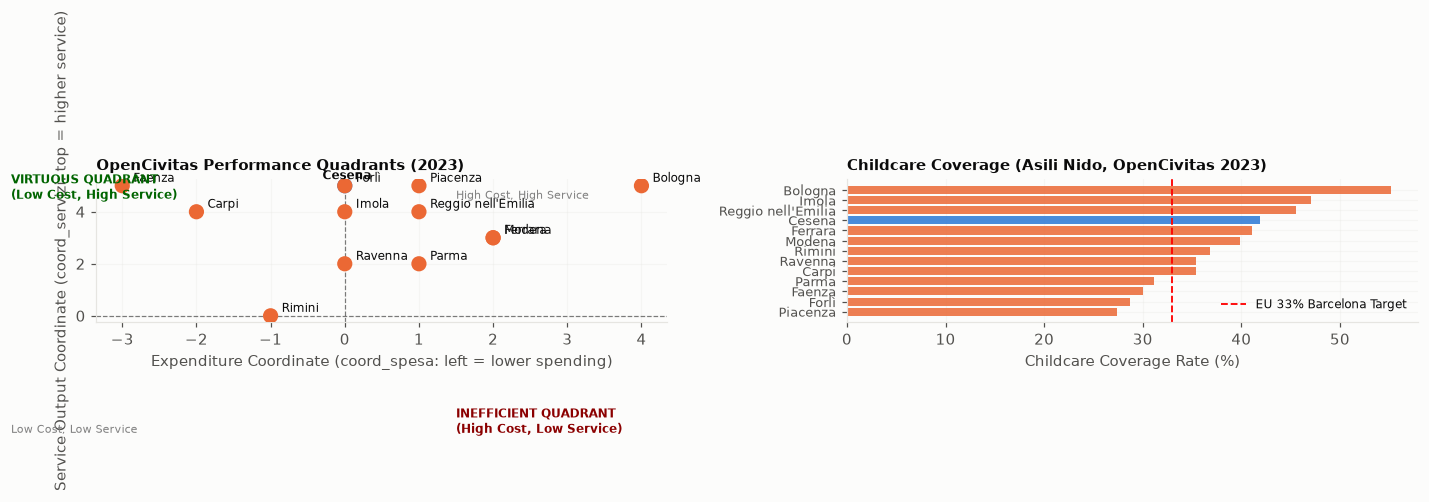

In [9]:
from cifresignificative.studies.cesena.analysis.opencivitas import (
    peer_standard_needs_comparison,
    comprensorio_standard_needs_comparison,
    social_and_childcare_benchmarks,
)

# 1. Peer Comparison on Fundamental Functions (OpenCivitas 2023)
peer_needs = peer_standard_needs_comparison()
print("SOSE / MEF OpenCivitas Standard Needs & Service Levels across 13 ER Municipalities (2023):")
display(peer_needs.peers_df[[
    "comune", "tot_spesa_storica_eur_pc", "tot_fabbisogno_standard_eur_pc",
    "tot_diff_eur_pc", "tot_diff_pct", "tot_livello_spesa_0_10",
    "tot_livello_servizi_0_10", "tot_coord_spesa", "tot_coord_servizi", "quadrante_performance"
]].round(2))

# 2. Social Services & Childcare Benchmarks
soc_sum = social_and_childcare_benchmarks()
print("\nSocial Services & Childcare Provision (OpenCivitas 2023):")
display(soc_sum.social_df[[
    "comune", "soc_spesa_storica_eur_pc", "soc_fabbisogno_standard_eur_pc",
    "copertura_nidi_pct", "deprivazione_indice", "gestione_associata_sociale", "soc_coord_servizi"
]].round(2))

# 3. Dual-Panel Visualization: Efficiency Quadrant & Childcare Coverage
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: OpenCivitas Performance Positioning (-5 to +5 Coordinates)
df_p = peer_needs.peers_df
colors_pts = [ITALY_C if c == "Cesena" else EU_C for c in df_p["comune"]]

axes[0].scatter(df_p["tot_coord_spesa"], df_p["tot_coord_servizi"], color=colors_pts, s=80, zorder=3)
for _, row in df_p.iterrows():
    dx = 0.15 if row["comune"] != "Cesena" else -0.3
    dy = 0.15 if row["comune"] != "Cesena" else 0.25
    axes[0].text(row["tot_coord_spesa"] + dx, row["tot_coord_servizi"] + dy, row["comune"], fontsize=8,
                 fontweight="bold" if row["comune"] == "Cesena" else "normal")

axes[0].axvline(0, color="k", ls="--", lw=0.8, alpha=0.5)
axes[0].axhline(0, color="k", ls="--", lw=0.8, alpha=0.5)
axes[0].set_xlabel("Expenditure Coordinate (coord_spesa: left = lower spending)")
axes[0].set_ylabel("Service Output Coordinate (coord_servizi: top = higher service)")
axes[0].set_title("OpenCivitas Performance Quadrants (2023)", fontsize=9.5)
axes[0].grid(alpha=0.3)
axes[0].text(-4.5, 4.5, "VIRTUOUS QUADRANT\n(Low Cost, High Service)", color="darkgreen", fontsize=8, fontweight="bold")
axes[0].text(1.5, 4.5, "High Cost, High Service", color="gray", fontsize=7.5)
axes[0].text(-4.5, -4.5, "Low Cost, Low Service", color="gray", fontsize=7.5)
axes[0].text(1.5, -4.5, "INEFFICIENT QUADRANT\n(High Cost, Low Service)", color="darkred", fontsize=8, fontweight="bold")

# Panel 2: Childcare Coverage Rate (%) across 13 Peers
df_nidi = soc_sum.social_df.sort_values("copertura_nidi_pct", ascending=True)
y_pos = np.arange(len(df_nidi))
colors_nidi = [ITALY_C if c == "Cesena" else EU_C for c in df_nidi["comune"]]

axes[1].barh(y_pos, df_nidi["copertura_nidi_pct"], color=colors_nidi, alpha=0.85)
axes[1].set_yticks(y_pos, df_nidi["comune"], fontsize=8.5)
axes[1].axvline(33.0, color="red", ls="--", lw=1.2, label="EU 33% Barcelona Target")
axes[1].set_xlabel("Childcare Coverage Rate (%)")
axes[1].set_title("Childcare Coverage (Asili Nido, OpenCivitas 2023)", fontsize=9.5)
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.show()

## 5b. Rigidity after 2021: a cash proxy from SIOPE (2017–2024)
The accrual series ends in 2018 for personnel and in 2021 for the rest, and no public per-municipality accrual source exists after 2021 (OpenBilanci stops at 2021; OpenBDAP publishes only national and macro-area aggregates). SIOPE gives cash payments and collections to 2024, so a cash proxy is computed: `(personnel + interest + loan repayment) / current revenue`. It is checked against the official ratio on the years where both exist (2017–2018) and never joined to it. The waste tax (TARI/TARSU) is booked in the municipal budget in some cities and collected through the operator's tariff in others, and Cesena changed in 2023, so the ratio is also shown without it in current revenue.

In [10]:
import pandas as pd
from cifresignificative.core.geo import CESENA, CORE_PEER_IDS

cp = pd.read_parquet("data/processed/cesena/siope_cash_panel.parquet")
cp = cp[cp["entity_type"] == "comune"]
core = [c for c in CORE_PEER_IDS if c != CESENA]
for col in ["rigidity_cash_pct", "rigidity_cash_ex_tari_pct"]:
    w = cp.pivot(index="year", columns="comune_id", values=col)
    out = pd.DataFrame({"cesena": w[CESENA], "core_median": w[core].median(axis=1), "all_peer_median": w.drop(columns=CESENA).median(axis=1)}).round(1)
    print(col); display(out)
acc = fiscal[(fiscal["regime"] == "dlgs118") & (fiscal["budget_type"] == "consuntivo") & fiscal["year"].isin([2017, 2018])][["comune_id", "year", "rigidity_official_pct"]]
both = cp[cp["year"].isin([2017, 2018])][["comune_id", "year", "rigidity_cash_pct"]].merge(acc, on=["comune_id", "year"]).dropna()
print(f"Anchor 2017-2018: {len(both)} city-years, correlation of the cash proxy with the official ratio {both.rigidity_cash_pct.corr(both.rigidity_official_pct):.2f}, mean gap {(both.rigidity_cash_pct - both.rigidity_official_pct).mean():+.1f} points")
print("Waste tax collected in the municipal budget (million euro, cash):")
display((cp.pivot(index="comune_id", columns="year", values="tari_tarsu_cassa_eur") / 1e6).round(1))

rigidity_cash_pct


,cesena,core_median,all_peer_median
year,,,
2016,NaN,NaN,NaN
2017,29.0,27.4,27.1
2018,27.8,26.6,26.6
2019,27.3,25.7,25.2
2020,27.1,24.4,24.4
2021,25.3,24.3,24.3
2022,26.6,26.1,24.5
2023,29.8,24.8,25.7
2024,29.0,24.7,24.5


rigidity_cash_ex_tari_pct


,cesena,core_median,all_peer_median
year,,,
2016,NaN,NaN,NaN
2017,36.2,34.9,33.0
2018,33.8,31.7,31.3
2019,33.5,30.7,30.1
2020,32.6,28.0,27.7
2021,31.1,28.8,28.8
2022,32.0,28.3,27.7
2023,30.8,27.9,29.1
2024,29.7,28.5,27.4


Anchor 2017-2018: 26 city-years, correlation of the cash proxy with the official ratio 0.97, mean gap +0.2 points
Waste tax collected in the municipal budget (million euro, cash):


year,2016,2017,2018,2019,2020,2021,2022,2023,2024
comune_id,,,,,,,,,
033032,NaN,20.7,19.7,20.5,17.0,20.5,22.0,20.9,22.8
034027,NaN,36.0,34.5,36.7,31.6,29.8,42.2,15.4,5.7
035033,NaN,32.2,34.6,36.0,32.3,30.9,11.9,3.6,2.0
036005,NaN,0.4,1.0,0.3,0.1,0.0,0.0,0.1,0.0
036023,NaN,37.7,35.5,36.5,32.6,34.9,37.7,34.5,36.9
037006,NaN,99.2,100.3,98.3,89.5,100.5,93.8,100.2,100.5
037032,NaN,10.4,10.6,9.9,9.1,9.5,9.4,8.8,2.1
038008,NaN,27.9,4.5,1.4,0.9,1.0,1.0,1.3,0.6
039010,NaN,10.4,12.2,9.8,5.3,9.7,11.5,10.0,11.3


## Takeaways (Pillar 1 — Municipal Fiscal Policy, 13 ER Municipalities; Descriptive)

- **Current spending is low (`robust`).** Cesena ranks near the bottom of the 13 cities on direct current spending in both accounting regimes, which are never compared with each other.
- **Capital spending is middling (`sensitive`).** The average depends on 2019. The city used more loans and fewer grants than most peers; FPV is a stock, not a funding source.
- **Taxes are low (`robust`).** The municipal IRPEF surcharge per resident is the lowest of the 13 in 2024. Budget rigidity in 2016–2018 is not unusually low; in 2019–2024 the cash proxy puts it above the Core Peer median, and whether it rose or fell depends on the waste-tax regime.
- **The Unione narrows the gap but does not close it (`sensitive`).** After netting transfers, consolidated current spending stays low against all 12 peers and close to Core Peers. Unione spending is split by population, and perimeters still differ.
- **OpenCivitas (`sensitive`).** The official low-spend, high-output placement holds but is shared with several peers, and it measures quantities.
- **Limits.** All statements are descriptive associations for one municipality, never causal claims. The figures are in the table below and in `reports/findings.md`, both computed by `analysis/claims.py`.

In [11]:
from cifresignificative.studies.cesena.analysis.claims import claims_for_notebook

print("Figures behind this notebook, computed from the processed tables (the same ones quoted in reports/findings.md):")
with pd.option_context("display.max_rows", None, "display.max_colwidth", 60):
    display(claims_for_notebook("01"))

Figures behind this notebook, computed from the processed tables (the same ones quoted in reports/findings.md):


,id,text,window,source
0,current_0815,€842,2008-2015,fiscal.parquet
1,current_0815_rank,#13 of 13,2008-2015,fiscal.parquet
2,current_0815_peer,€941,2008-2015,fiscal.parquet
3,current_1621,€835,2016-2021,fiscal.parquet
4,current_1621_rank,#11 of 13,2016-2021,fiscal.parquet
5,current_1621_peer,€943,2016-2021,fiscal.parquet
6,capital_1621,€166,2016-2021,fiscal.parquet
7,capital_1621_rank,#7 of 13,2016-2021,fiscal.parquet
8,capital_1621_peer,€128,2016-2021,fiscal.parquet
9,loans_1621,€45,2016-2021,fiscal.parquet
